# Workshop 3 — Gold Layer Preview

This notebook reads the two Gold datasets that the `gold_processing` DAG publishes in `datalake_gold/` and shows what each one contains. They are the only data source planned for the Plotly Dash dashboard (Workshop 4).

- **Governance** (`governance_YYYYMMDD_HHMMSS.parquet`): data health. Processing history per topic, missing values per field, pipeline state per source, Airflow run compliance and cross-source matching coverage.
- **Storytelling** (`storytelling_YYYYMMDD_HHMMSS.parquet`): what the monitoring analyst sees. Recent earthquakes with their bulletin and Tsunami Relevance Level, the regional historical baseline, the indicator distribution and its validation, and the catalog summaries.

Both are long tables: a `topic` (governance) or `metric` (storytelling) column says which indicator a row belongs to, and only the columns of that indicator are filled. The Tsunami Relevance Level is a monitoring aid, **not** a tsunami prediction or warning.

In [1]:
%matplotlib inline

import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
gold_root = project_root / os.environ.get("GOLD_DIR", "datalake_gold")


def complete(path):
    """A Spark Parquet folder is complete once _SUCCESS is written."""
    return path.is_file() or ((path / "_SUCCESS").is_file() and any(path.glob("part-*.parquet")))


def latest_pair(folder):
    for candidate in sorted(folder.glob("governance_*.parquet"), reverse=True):
        stamp = candidate.stem.removeprefix("governance_")
        partner = folder / f"storytelling_{stamp}.parquet"
        if re.fullmatch(r"\d{8}_\d{6}", stamp) and complete(candidate) and complete(partner):
            return stamp, candidate, partner
    return None


# Latest local Gold run; on a fresh clone, the committed samples
pair = latest_pair(gold_root) or latest_pair(gold_root / "samples")
if pair is None:
    raise FileNotFoundError("No Gold run found: trigger the gold_processing DAG first")
stamp, governance_path, storytelling_path = pair
governance = pd.read_parquet(governance_path)
storytelling = pd.read_parquet(storytelling_path)
print(f"Gold run {stamp}: {governance_path.relative_to(project_root)}, {storytelling_path.relative_to(project_root)}")
print(f"governance: {governance.shape[0]} rows x {governance.shape[1]} columns")
print(f"storytelling: {storytelling.shape[0]} rows x {storytelling.shape[1]} columns")

Gold run 20261121_142619: datalake_gold/governance_20261121_142619.parquet, datalake_gold/storytelling_20261121_142619.parquet
governance: 102 rows x 32 columns
storytelling: 816 rows x 28 columns


In [2]:
def filled(frame):
    """Only the columns an indicator uses."""
    return frame.dropna(axis=1, how="all")


display(governance.groupby("topic").size().rename("rows").to_frame())
display(storytelling.groupby("metric").size().rename("rows").to_frame())

,rows
topic,
earthquakes,2
matching,3
null_rate,84
orchestration,4
pipeline_state,5
rejected_records,1
tsunami_bulletins,2
tsunami_events,1


,rows
metric,
bulletins_by_center,2
earthquake_magnitude_distribution,37
earthquakes_by_year,18
historical_tsunamis_by_year,16
recent_earthquakes,607
regional_baseline,105
relevance_level_distribution,5
relevance_validation,2
tsunami_max_water_height_distribution,24


## 1. Governance

### Processing history and current quality per topic
Silver keeps every run, so the same observation appears once per run. `rows_processed` counts all Silver rows, `unique_observations` the latest version per source key, and `repeated_rows` the difference (the duplicate rate before and after consolidation).

In [3]:
topics = ["earthquakes", "tsunami_events", "tsunami_bulletins", "rejected_records"]
history = filled(governance[governance["topic"].isin(topics)]).set_index(["topic", "source"])
history["duplicate_rate_pct"] = (100 * history["repeated_rows"] / history["rows_processed"]).round(2)
history

rows_processed  unique_observations  repeated_rows  missing_coordinates  missing_coordinates_pct  incomplete_times  \
topic             source                                                                                                                              
earthquakes       usgs_fdsn              3891.0               1941.0         1950.0                  0.0                     0.00               0.0   
                  usgs_realtime         16578.0                788.0        15790.0                  0.0                     0.00               0.0   
tsunami_events    noaa_hazel              459.0                221.0          238.0                  9.0                     4.07              32.0   
tsunami_bulletins ptwc                      5.0                  3.0            2.0                  0.0                     0.00               0.0   
                  ntwc                      5.0                  2.0            3.0                  0.0                     0.00               0.0   
rejected_records  usgs_fdsn                 NaN                  NaN            NaN                  NaN                      NaN               NaN   

                                 incomplete_times_pct  rejected_records         iqr_field  iqr_outliers  unique_rejected_records  duplicate_rate_pct  
topic             source                                                                                                                              
earthquakes       usgs_fdsn                      0.00               NaN          depth_km         325.0                      NaN               50.12  
                  usgs_realtime                  0.00               NaN          depth_km         124.0                      NaN               95.25  
tsunami_events    noaa_hazel                    14.48               NaN  max_water_height          33.0                      NaN               51.85  
tsunami_bulletins ptwc                           0.00               NaN              None           NaN                      NaN               40.00  
                  ntwc                           0.00               NaN              None           NaN                      NaN               60.00  
rejected_records  usgs_fdsn                       NaN               2.0              None           NaN                      1.0                 NaN

### Missing values per field
Share of null (or NaN) values per field, topic and source, over the current observations. Fields that are always filled are left out of this view.

In [4]:
nulls = governance[governance["topic"].eq("null_rate")][["source", "field", "null_count", "null_rate_pct"]]
nulls[nulls["null_rate_pct"] > 0].sort_values("null_rate_pct", ascending=False).reset_index(drop=True)

,source,field,null_count,null_rate_pct
0,usgs_fdsn,tsunami_bulletin_flag,1941.0,100.00
1,noaa_hazel,warning_status_id,169.0,76.47
2,noaa_hazel,reported_eq_magnitude,35.0,15.84
3,noaa_hazel,reported_eq_depth,35.0,15.84
4,noaa_hazel,noaa_earthquake_event_id,34.0,15.38
5,noaa_hazel,seconds,32.0,14.48
6,noaa_hazel,event_time,32.0,14.48
7,noaa_hazel,known_hour,23.0,10.41
8,noaa_hazel,known_minute,23.0,10.41
9,noaa_hazel,max_water_height,12.0,5.43


### Pipeline state, orchestration and matching
- **Pipeline state (US5):** last successful load and watermark age per source, read from PostgreSQL when Gold runs.
- **Orchestration:** successful Airflow runs in the window against the runs each schedule should produce.
- **Matching:** tsunamis and bulletins that could be linked to an earthquake, and how many links were accepted or are pending review.

In [5]:
for topic in ["pipeline_state", "orchestration", "matching"]:
    print(topic)
    display(filled(governance[governance["topic"].eq(topic)]).drop(columns="topic").reset_index(drop=True))

pipeline_state


,source,last_successful_run_at,watermark_at,watermark_age_hours,load_runs_window,failed_load_runs_window
0,noaa_hazel,2026-11-20 00:50:11.337959,NaT,NaN,3.0,0.0
1,ntwc,2026-11-21 05:00:08.391428,2026-11-21 04:32:57.000,9.88,5.0,0.0
2,ptwc,2026-11-21 05:00:08.400649,2026-11-21 00:19:13.000,14.11,5.0,0.0
3,usgs_fdsn,2026-11-21 14:20:09.518841,2026-11-21 12:40:35.300,1.76,5.0,0.0
4,usgs_realtime,2026-11-21 14:20:09.505881,2026-11-21 13:20:24.821,1.09,25.0,0.0


orchestration


,dag_id,successful_dag_runs,failed_dag_runs,expected_dag_runs,run_compliance_pct
0,incremental_ingestion,44.0,0.0,1008.0,4.37
1,silver_processing,50.0,1.0,1008.0,4.96
2,usgs_fdsn_reconciliation,2.0,0.0,7.0,28.57
3,gold_processing,7.0,0.0,7.0,100.00


matching


,source,relation_type,eligible,accepted_links,pending_links,unmatched,coverage_pct
0,ptwc,reports_on,3.0,0.0,3.0,0.0,0.00
1,ntwc,reports_on,2.0,0.0,0.0,2.0,0.00
2,noaa_hazel,caused_by,185.0,163.0,12.0,10.0,88.11


## 2. Storytelling

### Recent earthquakes (US1, US2, US4)
USGS real-time earthquakes with M ≥ 4.5 inside the Pacific query area. Earthquakes with M ≥ 6 carry the Tsunami Relevance Level and its points; any earthquake can carry the official bulletin linked to it.

In [6]:
recent = storytelling[storytelling["metric"].eq("recent_earthquakes")]  # all columns: a link may be absent today
print(f"{len(recent)} recent earthquakes, {recent['relevance_level'].notna().sum()} with a relevance level, "
      f"{recent['bulletin_source'].notna().sum()} with a linked bulletin")
columns = ["external_id", "event_time", "magnitude", "depth_km", "place", "relevance_level", "relevance_points",
           "history_tsunamis", "bulletin_source", "bulletin_severity"]
recent[[c for c in columns if c in recent]].sort_values(["relevance_points", "magnitude"], ascending=False).head(12)

607 recent earthquakes, 19 with a relevance level, 0 with a linked bulletin


,external_id,event_time,magnitude,depth_km,place,relevance_level,relevance_points,history_tsunamis,bulletin_source,bulletin_severity
411,us6000u4j2,2026-10-24 02:31:28.880,6.8,16.000,"203 km NW of Port-Olry, Vanuatu",MODERATE,3.0,3.0,None,None
485,us7000tymu,2026-11-16 21:11:20.488,6.6,68.000,"149 km WSW of Tual, Indonesia",MODERATE,3.0,1.0,None,None
235,us7000tx16,2026-11-09 03:34:59.466,6.4,17.000,"30 km WSW of Lata, Solomon Islands",MODERATE,3.0,4.0,None,None
215,us6000u3jl,2026-10-20 04:20:38.782,6.3,16.000,"202 km NW of Port-Olry, Vanuatu",MODERATE,3.0,3.0,None,None
326,us6000u4jb,2026-10-24 02:35:57.344,6.1,10.000,"163 km NW of Port-Olry, Vanuatu",MODERATE,3.0,4.0,None,None
692,us7000twg9,2026-11-06 10:39:27.869,6.1,29.000,"144 km SE of Hasaki, Japan",MODERATE,3.0,2.0,None,None
289,us7000ttlm,2026-10-28 02:21:44.755,6.0,10.000,"208 km NW of Port-Olry, Vanuatu",MODERATE,3.0,3.0,None,None
298,us7000tupl,2026-11-01 11:47:04.007,6.0,12.000,"164 km NW of Port-Olry, Vanuatu",MODERATE,3.0,4.0,None,None
519,us6000u3bc,2026-10-19 07:49:04.693,6.0,10.000,"184 km NW of Port-Olry, Vanuatu",MODERATE,3.0,4.0,None,None
154,us6000ucij,2026-11-21 09:42:09.120,6.8,132.055,"105 km NE of Lospalos, Timor Leste",LOW,2.0,1.0,None,None


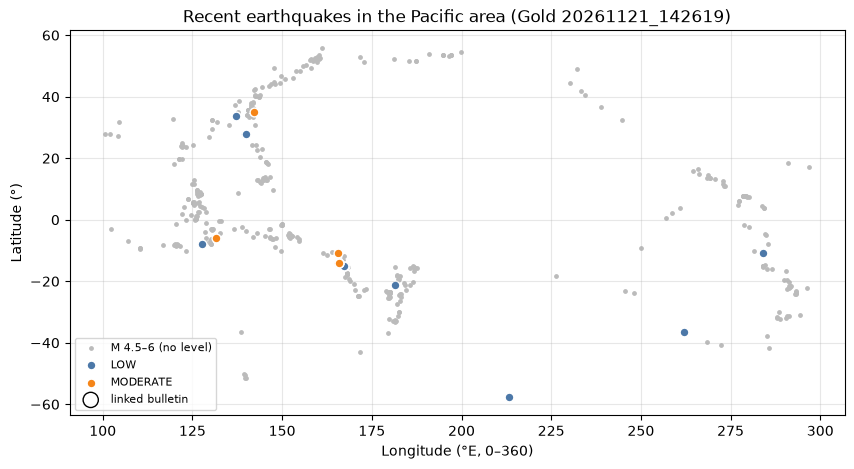

In [7]:
colors = {"LOW": "#4c78a8", "MODERATE": "#f58518", "HIGH": "#e45756", "OFFICIAL ALERT": "#000000"}
longitude = recent["longitude"].where(recent["longitude"] >= 0, recent["longitude"] + 360)  # Pacific-centred
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(longitude, recent["latitude"], s=6, color="#bbbbbb", label="M 4.5–6 (no level)")
for level, color in colors.items():
    rows = recent["relevance_level"].eq(level)
    if rows.any():
        ax.scatter(longitude[rows], recent.loc[rows, "latitude"], s=40, color=color, edgecolor="white", label=level)
linked = recent["bulletin_source"].notna()
ax.scatter(longitude[linked], recent.loc[linked, "latitude"], s=120, facecolor="none", edgecolor="black",
           label="linked bulletin")
ax.set(xlabel="Longitude (°E, 0–360)", ylabel="Latitude (°)", title=f"Recent earthquakes in the Pacific area (Gold {stamp})")
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.3)
plt.show()

### Tsunami Relevance Level over the catalog (US4)
The Workshop 1 rule scores magnitude, depth and earlier probable or definite tsunamis within 300 km; deep earthquakes stay LOW and a linked Moderate or higher CAP bulletin becomes OFFICIAL ALERT. The validation rows are the two measures proposed in Workshop 1, computed on the 2010–2025 USGS FDSN catalog with the accepted tsunami–earthquake links.

In [8]:
levels = storytelling[storytelling["metric"].eq("relevance_level_distribution")]
display(levels.pivot_table(index="relevance_level", columns="source", values="count", fill_value=0)
        .reindex([l for l in ["LOW", "MODERATE", "HIGH", "OFFICIAL ALERT"] if l in set(levels["relevance_level"])]))
validation = storytelling[storytelling["metric"].eq("relevance_validation")]
validation[["unit", "count", "value"]].rename(columns={"unit": "measure", "count": "earthquakes", "value": "percent"})

source,usgs_fdsn,usgs_realtime
relevance_level,,
LOW,1059.0,10.0
MODERATE,790.0,10.0
HIGH,92.0,0.0


,measure,earthquakes,percent
814,not linked rated HIGH or higher (%),1778,1.41
815,tsunami-linked rated MODERATE or higher (%),163,89.57


### Regional historical baseline (US3)
Historical M ≥ 6 earthquakes (USGS FDSN 2010–2025) and probable or definite tsunamis (NOAA HazEL) per 10° latitude/longitude cell. A recent earthquake is compared with the row of its own `region_cell`.

In [9]:
baseline = filled(storytelling[storytelling["metric"].eq("regional_baseline")]).drop(columns=["metric", "source"])
baseline.rename(columns={"count": "historical_earthquakes"}).sort_values("historical_earthquakes", ascending=False).head(10)

,historical_earthquakes,region_cell,historical_tsunamis,max_magnitude,max_water_height_m
722,160,"lat -20..-10, lon 160..170",23.0,8.0,11.00
784,118,"lat 30..40, lon 140..150",16.0,9.1,39.26
712,110,"lat -10..0, lon 150..160",13.0,7.9,7.52
756,109,"lat 0..10, lon 120..130",7.0,7.6,5.00
725,99,"lat -30..-20, lon -180..-170",13.0,8.1,22.00
715,85,"lat -20..-10, lon -180..-170",2.0,8.2,0.12
736,79,"lat -40..-30, lon -80..-70",7.0,8.8,29.00
711,71,"lat -10..0, lon 140..150",1.0,7.6,1.00
709,62,"lat -10..0, lon 120..130",2.0,7.3,1.50
730,55,"lat -30..-20, lon 170..180",8.0,7.7,0.78


### Catalog summaries
Annual counts and distributions per source, kept from the first Gold version.

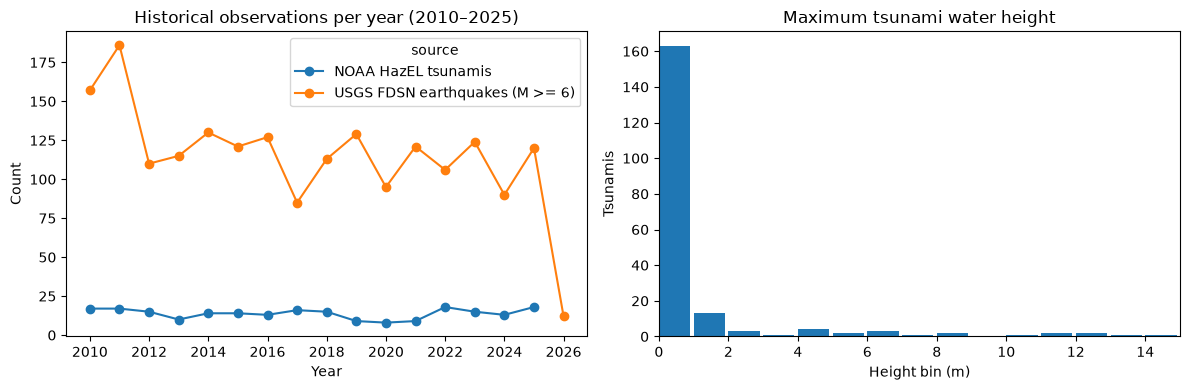

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Historical sources only: the 2026 real-time feed (M >= 4.5, 30 days) is not comparable with the M >= 6 catalog
years = storytelling[storytelling["metric"].isin(["earthquakes_by_year", "historical_tsunamis_by_year"])
                     & storytelling["source"].isin(["usgs_fdsn", "noaa_hazel"])]
labels = {"usgs_fdsn": "USGS FDSN earthquakes (M >= 6)", "noaa_hazel": "NOAA HazEL tsunamis"}
years.pivot_table(index="year", columns="source", values="count", aggfunc="sum").rename(columns=labels).plot(
    ax=axes[0], marker="o")
axes[0].set(title="Historical observations per year (2010–2025)", xlabel="Year", ylabel="Count")
heights = storytelling[storytelling["metric"].eq("tsunami_max_water_height_distribution")].sort_values("bin_start")
axes[1].bar(heights["bin_start"], heights["count"], width=0.9, align="edge")
axes[1].set(title="Maximum tsunami water height", xlabel="Height bin (m)", ylabel="Tsunamis")
axes[1].set_xlim(0, 15)
plt.tight_layout()
plt.show()

## 3. Reading the Gold files elsewhere
The dashboard will read the same two folders. With pandas, a Spark Parquet folder is read like a single file (`pd.read_parquet(folder)`); with PySpark, `spark.read.parquet(folder)`. Filter by `topic` or `metric` first, then keep the columns of that indicator.